Our mission is to use the chemical measurements of white to train a neural network that predicts wine quality

In [1]:
import torch
from torch import nn
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [3]:
import os
print(os.getcwd())

c:\Users\Mumba Mumba\Desktop\tensor flow\myfirstlesson_on_nn\notebooks


In [7]:
df = pd.read_csv("data/Concrete_Data.xls", sep=';')
print(df.head())
print(df.info())
print(df.describe())
print("Missing values:\n", df.isnull().sum())

FileNotFoundError: [Errno 2] No such file or directory: 'data/Concrete_Data.xls'

In [ ]:
#separate features from the target
X = df.drop(columns=['quality'])
y = df['quality']

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Quality values:\n", y.value_counts().sort_index())

#split the data into training and testing test

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Features shape: (4898, 11)
Target shape: (4898,)
Quality values:
 quality
3      20
4     163
5    1457
6    2198
7     880
8     175
9       5
Name: count, dtype: int64
Training samples: 3918
Testing samples: 980


In [ ]:
import torch

# Convert only variables that are pandas objects
if not isinstance(X_train, torch.Tensor):
    X_train = torch.tensor(X_train.to_numpy(), dtype=torch.float32)

if not isinstance(X_test, torch.Tensor):
    X_test = torch.tensor(X_test.to_numpy(), dtype=torch.float32)

if not isinstance(y_train, torch.Tensor):
    y_train = torch.tensor(y_train.to_numpy(), dtype=torch.float32).reshape(-1, 1)

if not isinstance(y_test, torch.Tensor):
    y_test = torch.tensor(y_test.to_numpy(), dtype=torch.float32).reshape(-1, 1)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: torch.Size([3918, 11])
y_train: torch.Size([3918, 1])
X_test: torch.Size([980, 11])
y_test: torch.Size([980, 1])


In [ ]:
torch.manual_seed(42)
class WineQualityModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(11, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16,1)
        )

    def forward(self, x):
        return self.network(x)

model = WineQualityModel()
print(model)

model.eval()
with torch.no_grad():
    predictions = model(X_train[:5])

print("Predictions:")
print(predictions)

print("Actual quality scores:")
print(y_train[:5])

WineQualityModel(
  (network): Sequential(
    (0): Linear(in_features=11, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)
Predictions:
tensor([[1.7585],
        [2.3913],
        [1.0686],
        [1.2227],
        [2.0128]])
Actual quality scores:
tensor([[6.],
        [5.],
        [6.],
        [7.],
        [5.]])


In [ ]:
#calculate the inital loss

loss_fn = nn.MSELoss()
with torch.no_grad():
    initial_predictions = model(X_train)
    initial_loss = loss_fn(initial_predictions , y_train)

print("Initial Training Loss:", initial_loss.item())

Initial Training Loss: 20.95263671875


In [ ]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr = 0.001
)

In [ ]:
epochs = 100

for epoch in range(epochs):
    predictions = model(X_train)

    loss = loss_fn(predictions, y_train)

    optimizer.zero_grad(0)

    loss.backward()

    optimizer.step()

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss.item():.4f}")

Epoch 10/100, Loss: 4.9330
Epoch 20/100, Loss: 5.4060
Epoch 30/100, Loss: 4.3135
Epoch 40/100, Loss: 3.8048
Epoch 50/100, Loss: 3.2486
Epoch 60/100, Loss: 2.7614
Epoch 70/100, Loss: 2.3335
Epoch 80/100, Loss: 1.9266
Epoch 90/100, Loss: 1.5575
Epoch 100/100, Loss: 1.1721


In [ ]:
for name, parameter in model.named_parameters():
    print(name)
    print(parameter.detach())

network.0.weight
tensor([[ 0.3559,  0.3701,  0.0535,  0.2844,  0.0515,  0.1368, -0.0632,  0.3043,
          0.3937, -0.0937,  0.3924],
        [ 0.1031,  0.2633,  0.0841,  0.1249, -0.0103,  0.2359,  0.0501, -0.0919,
          0.1265, -0.0914,  0.0214],
        [-0.1050,  0.2154, -0.2197, -0.1316, -0.0711, -0.1674,  0.0365, -0.2787,
          0.2916, -0.2377,  0.2536],
        [ 0.0346, -0.1139,  0.1707,  0.0333,  0.2279,  0.0154, -0.1122,  0.0648,
         -0.0982,  0.1113,  0.2527],
        [ 0.1743, -0.1318,  0.1741,  0.0539,  0.1531, -0.1838, -0.2985, -0.1165,
         -0.2313,  0.2474,  0.0868],
        [ 0.1249,  0.0954, -0.0052,  0.2360, -0.2142,  0.0190, -0.2058,  0.0930,
         -0.1038,  0.0924, -0.0628],
        [ 0.2169, -0.2074, -0.2105, -0.1686,  0.2482,  0.0971,  0.2844, -0.2836,
         -0.3344, -0.2698, -0.2439],
        [ 0.1221,  0.1080,  0.2505, -0.1557, -0.2055,  0.1600, -0.1219,  0.1830,
         -0.0715,  0.1725, -0.2343],
        [-0.1522,  0.0919,  0.0637, -0.

In [ ]:
#model evaluations
model.eval()
with torch.no_grad():
    test_predictions = model(X_test)

print("First 10 predictions:")
print(test_predictions[:10])

print("\nFirst 10 actual values:")
print(y_test[:10])

with torch.no_grad():
    test_loss = loss_fn(test_predictions, y_test)

print('Test MSE:', test_loss.item())

First 10 predictions:
tensor([[5.9731],
        [5.6588],
        [5.7225],
        [5.6771],
        [5.3537],
        [6.4918],
        [6.7309],
        [5.3435],
        [5.0354],
        [6.6571]])

First 10 actual values:
tensor([[7.],
        [8.],
        [8.],
        [5.],
        [7.],
        [6.],
        [5.],
        [4.],
        [6.],
        [5.]])
Test MSE: 1.2916287183761597


In [ ]:
comparison = pd.DataFrame({
    "Actual": y_test[:20].flatten().numpy(),
    "Predicted": test_predictions[:20].flatten().numpy()
})

comparison["Error"] = comparison["Predicted"] - comparison["Actual"]

display(comparison)

,Actual,Predicted,Error
0,7.0,5.973096,-1.026904
1,8.0,5.658849,-2.341151
2,8.0,5.722537,-2.277463
3,5.0,5.677074,0.677074
4,7.0,5.353662,-1.646338
5,6.0,6.491816,0.491816
6,5.0,6.730948,1.730948
7,4.0,5.343458,1.343458
8,6.0,5.035444,-0.964556
9,5.0,6.657096,1.657096


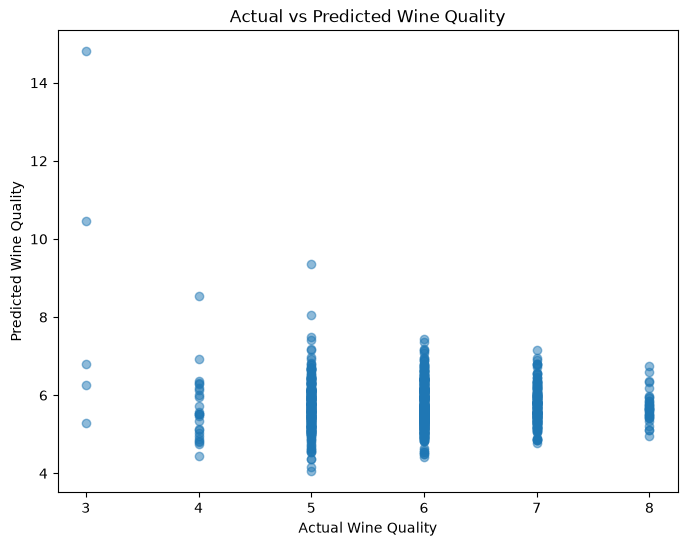

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test.numpy(),
    test_predictions.numpy(),
    alpha=0.5
)

plt.xlabel("Actual Wine Quality")
plt.ylabel("Predicted Wine Quality")
plt.title("Actual vs Predicted Wine Quality")

plt.show()

In [ ]:
# prediction for one new winw
sample = X_test[0].unsqueeze(0)

with torch.no_grad():
    prediction = model(sample)

print("Predicted quality:", prediction.item())
print("Actual quality:", y_test[0].item())

Predicted quality: 5.973095893859863
Actual quality: 7.0
